# Task 4: Trend Prediction Analysis

## Objective

The objective of this task is to analyze historical Netflix content trends and forecast future content growth.

The analysis focuses on the number of Netflix titles released each year. Historical yearly patterns will be examined before applying a forecasting model to estimate future content levels.

The task follows five main steps:

1. Prepare release-year data.
2. Analyze yearly content trends.
3. Build forecasting models.
4. Visualize future predictions.
5. Interpret the results.

In [1]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
from statsmodels.tsa.holtwinters import Holt

print("statsmodels is working")

statsmodels is working


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df_trend = pd.read_csv("../data/netflix_clean.csv")

print("Dataset shape:", df_trend.shape)

Dataset shape: (8786, 26)


## Step 1: Prepare release-year data

The `release_year` column represents the year in which each title was originally released.

I first check the range of release years and confirm that the column contains valid numeric values. I then aggregate the dataset by release year to calculate the number of titles released in each year.

This yearly count will form the time series used for trend analysis and forecasting.

In [4]:
# Check the release-year data

print("Missing release years:", df_trend["release_year"].isna().sum())
print("Earliest release year:", df_trend["release_year"].min())
print("Latest release year:", df_trend["release_year"].max())

# Count titles released in each year

release_year_counts = (
    df_trend
    .groupby("release_year")
    .size()
    .reset_index(name="content_count")
    .sort_values("release_year")
)

display(release_year_counts.head(10))
display(release_year_counts.tail(10))

Missing release years: 0
Earliest release year: 1925
Latest release year: 2021


,release_year,content_count
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4
5,1946,2
6,1947,1
7,1954,2
8,1955,3
9,1956,2


,release_year,content_count
64,2012,236
65,2013,286
66,2014,351
67,2015,555
68,2016,901
69,2017,1030
70,2018,1144
71,2019,1029
72,2020,953
73,2021,592


In [5]:
print("Number of release years:", len(release_year_counts))

Number of release years: 74


In [6]:
print("Release-year summary:")
display(release_year_counts.describe())

print("\nFirst 20 release years:")
display(release_year_counts.head(20))

print("\nLast 20 release years:")
display(release_year_counts.tail(20))

Release-year summary:


,release_year,content_count
count,74.000000,74.000000
mean,1983.581081,118.729730
std,23.157594,266.492915
min,1925.000000,1.000000
25%,1966.250000,3.000000
50%,1984.500000,12.500000
75%,2002.750000,57.000000
max,2021.000000,1144.000000



First 20 release years:


,release_year,content_count
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4
5,1946,2
6,1947,1
7,1954,2
8,1955,3
9,1956,2



Last 20 release years:


,release_year,content_count
54,2002,51
55,2003,59
56,2004,64
57,2005,80
58,2006,96
59,2007,88
60,2008,135
61,2009,152
62,2010,192
63,2011,185


## Step 2: Analyze yearly content trends

The dataset contains titles released between 1925 and 2021. The earliest years are relatively sparse, with many individual years containing only a small number of titles.

For the main trend analysis, I focus on the complete years from 1984 to 2020. The year 1984 is close to the median release year in the dataset and provides a practical starting point that retains a substantial portion of the historical data while reducing the influence of the very sparse early years.

This gives a continuous 37-year period for examining changes in content releases over time. The year 2021 is excluded because the dataset was collected during 2021 and therefore does not represent a complete year.

The earlier years from 1925 to 1983 are still part of the dataset and were considered when examining the overall release-year distribution, but they are excluded from the main forecasting window because their yearly counts are relatively small.

In [7]:
trend_data = release_year_counts[
    (release_year_counts["release_year"] >= 1984) &
    (release_year_counts["release_year"] <= 2020)
].copy()

print("Trend period:", trend_data["release_year"].min(), "to", trend_data["release_year"].max())
print("Number of years:", len(trend_data))

display(trend_data)

Trend period: 1984 to 2020
Number of years: 37


,release_year,content_count
36,1984,12
37,1985,10
38,1986,13
39,1987,8
40,1988,18
41,1989,16
42,1990,22
43,1991,17
44,1992,23
45,1993,28


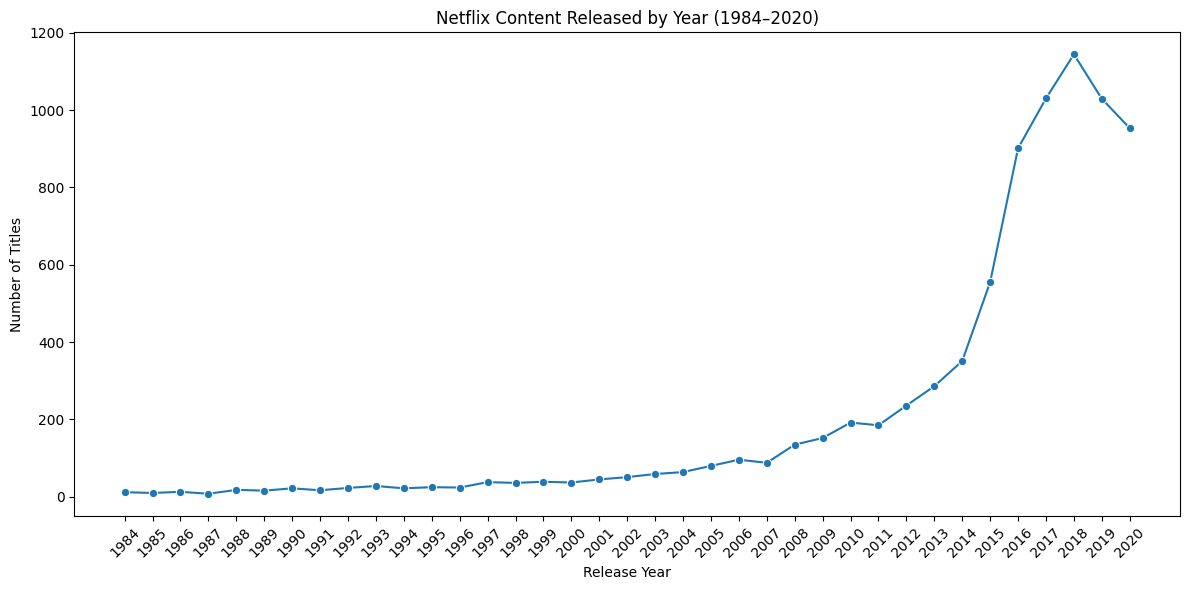

In [8]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=trend_data,
    x="release_year",
    y="content_count",
    marker="o"
)

plt.title("Netflix Content Released by Year (1984–2020)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(
    trend_data["release_year"],
    rotation=45
)

plt.tight_layout()
plt.show()

In [9]:
trend_data["year_over_year_change"] = (
    trend_data["content_count"].pct_change() * 100
)

display(trend_data)

,release_year,content_count,year_over_year_change
36,1984,12,NaN
37,1985,10,-16.666667
38,1986,13,30.000000
39,1987,8,-38.461538
40,1988,18,125.000000
41,1989,16,-11.111111
42,1990,22,37.500000
43,1991,17,-22.727273
44,1992,23,35.294118
45,1993,28,21.739130


In [10]:
print("Largest increase:")
display(
    trend_data.loc[
        trend_data["year_over_year_change"].idxmax()
    ]
)

print("\nLargest decrease:")
display(
    trend_data.loc[
        trend_data["year_over_year_change"].idxmin()
    ]
)

Largest increase:


release_year             1988.0
content_count              18.0
year_over_year_change     125.0
Name: 40, dtype: float64


Largest decrease:


release_year             1987.000000
content_count               8.000000
year_over_year_change     -38.461538
Name: 39, dtype: float64

### Trend interpretation

The release-year series shows a clear long-term increase in the number of titles represented in the dataset.

From 1984 to the early 2000s, yearly content counts remained relatively low and fluctuated considerably. Growth became more consistent after 2002, followed by a much stronger increase from 2015 onward. The number of titles reached a peak of 1,144 in 2018.

Content counts then declined to 1,029 in 2019 and 953 in 2020. Although these represent year-over-year decreases of approximately 10.1% and 7.4%, respectively, the counts remain substantially higher than those observed during the earlier part of the period.

The largest percentage increase occurred in 1988, at 125%. However, this increase was based on a small number of titles, increasing from 8 to 18. Therefore, percentage changes from years with very small counts should be interpreted cautiously.

Overall, the dataset shows long-term content growth, a sharp expansion between 2015 and 2018, and a moderate decline after the 2018 peak.

## Step 3: Build forecasting models

### Step 3.1: Create training and test data

To evaluate the forecasting approach, the historical data is divided into a training period and a test period.

The training data contains release years from 1984 to 2016. The test data contains the four most recent complete years, 2017 to 2020.

The model will be trained using only the training period and then used to predict the test period. The predictions can then be compared with the actual content counts.

This time-based split avoids using future observations to predict earlier observations.

In [11]:
# Create training and test datasets

train_data = trend_data[
    trend_data["release_year"] <= 2016
].copy()

test_data = trend_data[
    trend_data["release_year"] >= 2017
].copy()

print("Training period:", train_data["release_year"].min(), "to", train_data["release_year"].max())
print("Training years:", len(train_data))

print("\nTest period:", test_data["release_year"].min(), "to", test_data["release_year"].max())
print("Test years:", len(test_data))

display(train_data)
display(test_data)

Training period: 1984 to 2016
Training years: 33

Test period: 2017 to 2020
Test years: 4


,release_year,content_count,year_over_year_change
36,1984,12,NaN
37,1985,10,-16.666667
38,1986,13,30.000000
39,1987,8,-38.461538
40,1988,18,125.000000
41,1989,16,-11.111111
42,1990,22,37.500000
43,1991,17,-22.727273
44,1992,23,35.294118
45,1993,28,21.739130


,release_year,content_count,year_over_year_change
69,2017,1030,14.317425
70,2018,1144,11.067961
71,2019,1029,-10.052448
72,2020,953,-7.385811


### Step 3.3: Evaluate the naive baseline

The naive baseline is evaluated by comparing its predictions with the actual content counts in the test period.

The baseline assumes that each test year will have the same number of titles as the final year in the training period.

I use Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) to measure prediction error. Lower values indicate better predictive performance.

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Use the last observed training value as the baseline prediction
last_training_value = train_data["content_count"].iloc[-1]

# Create a fresh copy of the test data
baseline_results = test_data[
    ["release_year", "content_count"]
].copy()

# Apply the naive prediction to every test year
baseline_results["naive_prediction"] = last_training_value

# Calculate prediction errors
naive_mae = mean_absolute_error(
    baseline_results["content_count"],
    baseline_results["naive_prediction"]
)

naive_rmse = np.sqrt(
    mean_squared_error(
        baseline_results["content_count"],
        baseline_results["naive_prediction"]
    )
)

print(f"Last training value: {last_training_value}")
print(f"Naive baseline MAE: {naive_mae:.2f}")
print(f"Naive baseline RMSE: {naive_rmse:.2f}")

display(baseline_results)

Last training value: 901
Naive baseline MAE: 138.00
Naive baseline RMSE: 153.93


,release_year,content_count,naive_prediction
69,2017,1030,901
70,2018,1144,901
71,2019,1029,901
72,2020,953,901


### Step 3.4: Build a linear trend model

The second forecasting approach uses linear regression to model the relationship between release year and the number of titles.

The model is trained using the 1984–2016 training period. It then predicts the number of titles for the 2017–2020 test period.

The purpose is to determine whether a simple historical trend model can improve on the naive baseline.

In [13]:
from sklearn.linear_model import LinearRegression

# Prepare training features and target
X_train = train_data[["release_year"]]
y_train = train_data["content_count"]

# Create and fit the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict the test period
X_test = test_data[["release_year"]]
linear_predictions = linear_model.predict(X_test)

# Store predictions
linear_results = test_data[
    ["release_year", "content_count"]
].copy()

linear_results["linear_prediction"] = linear_predictions.round(2)

display(linear_results)

,release_year,content_count,linear_prediction
69,2017,1030,346.80
70,2018,1144,360.31
71,2019,1029,373.83
72,2020,953,387.34


In [14]:
linear_mae = mean_absolute_error(
    linear_results["content_count"],
    linear_results["linear_prediction"]
)

linear_rmse = np.sqrt(
    mean_squared_error(
        linear_results["content_count"],
        linear_results["linear_prediction"]
    )
)

print(f"Linear regression MAE: {linear_mae:.2f}")
print(f"Linear regression RMSE: {linear_rmse:.2f}")

Linear regression MAE: 671.93
Linear regression RMSE: 676.42


### Step 3.5: Build a Holt exponential smoothing model

The linear regression model performed poorly because the historical relationship between release year and content count is not linear.

To account for the changing level and recent trend in the time series, I use Holt's exponential smoothing method with a damped trend.

Exponential smoothing gives greater importance to more recent observations, while the damped trend prevents the forecast from extending a recent trend indefinitely.

The model is trained on the 1984–2016 period and evaluated on the same 2017–2020 test period.

In [15]:
from statsmodels.tsa.holtwinters import Holt

# Create an annual time-series index
train_series = train_data.copy()

train_series["release_year"] = pd.PeriodIndex(
    train_series["release_year"].astype(str),
    freq="Y"
)

train_series = train_series.set_index("release_year")["content_count"]

# Fit Holt's exponential smoothing model with a damped trend
holt_model = Holt(
    train_series,
    damped_trend=True,
    initialization_method="estimated"
).fit(optimized=True)

# Forecast the four test years
holt_predictions = holt_model.forecast(
    len(test_data)
)

# Create results table
holt_results = test_data[
    ["release_year", "content_count"]
].copy()

holt_results["holt_prediction"] = holt_predictions.values.round(2)

display(holt_results)

,release_year,content_count,holt_prediction
69,2017,1030,1245.27
70,2018,1144,1587.82
71,2019,1029,1928.65
72,2020,953,2267.79


In [16]:
holt_mae = mean_absolute_error(
    holt_results["content_count"],
    holt_results["holt_prediction"]
)

holt_rmse = np.sqrt(
    mean_squared_error(
        holt_results["content_count"],
        holt_results["holt_prediction"]
    )
)

print(f"Holt model MAE: {holt_mae:.2f}")
print(f"Holt model RMSE: {holt_rmse:.2f}")

Holt model MAE: 718.38
Holt model RMSE: 833.87


### Step 3.6: Compare forecasting models

The three forecasting approaches are compared using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

Both metrics are calculated on the same test period, 2017–2020, so the models can be compared fairly.

Lower MAE and RMSE indicate better forecasting performance.

The naive baseline achieved the lowest error, with an MAE of 138.00 and an RMSE of 153.93. Linear regression and Holt exponential smoothing performed substantially worse.

The poor performance of the linear and Holt models suggests that the historical release-year series does not follow a simple linear or continuously increasing trend. In particular, the strong growth before 2017 was followed by a peak in 2018 and declines in 2019 and 2020.

Therefore, the naive baseline is selected as the best-performing model among the three approaches tested. Although it is simple, it provides the most accurate predictions for the held-out test period.

In [17]:
# Compare model performance

model_comparison = pd.DataFrame({
    "model": [
        "Naive baseline",
        "Linear regression",
        "Holt exponential smoothing"
    ],
    "MAE": [
        naive_mae,
        linear_mae,
        holt_mae
    ],
    "RMSE": [
        naive_rmse,
        linear_rmse,
        holt_rmse
    ]
})

model_comparison = model_comparison.sort_values("MAE")

display(model_comparison)

,model,MAE,RMSE
0,Naive baseline,138.0000,153.930179
1,Linear regression,671.9300,676.415409
2,Holt exponential smoothing,718.3825,833.870528


## Step 4: Visualize future predictions

The naive baseline performed best on the held-out test period, so it is selected as the final forecasting approach.

For the future forecast, the complete historical period from 1984 to 2020 is used to identify the most recent observed content count. The last complete year is 2020, with 953 titles.

The naive baseline assumes that this most recent observed level remains constant over the forecast period.

The forecast should therefore be interpreted as a simple baseline estimate rather than a prediction of Netflix's actual future content production.

Although the dataset contains 592 titles for 2021, this value is excluded from model training and evaluation because the dataset only covers part of 2021. Therefore, 2021 is treated as the first forecast year in this analysis.

In [18]:
# Use the complete historical period for the final baseline forecast
final_training_data = trend_data.copy()

# Last observed complete year's content count
last_observed_year = final_training_data["release_year"].max()
last_observed_count = final_training_data["content_count"].iloc[-1]

print("Last observed year:", last_observed_year)
print("Last observed content count:", last_observed_count)

Last observed year: 2020
Last observed content count: 953


In [19]:
# Forecast the next five years
forecast_years = list(range(2021, 2026))

future_forecast = pd.DataFrame({
    "release_year": forecast_years,
    "forecast_count": last_observed_count
})

display(future_forecast)

,release_year,forecast_count
0,2021,953
1,2022,953
2,2023,953
3,2024,953
4,2025,953


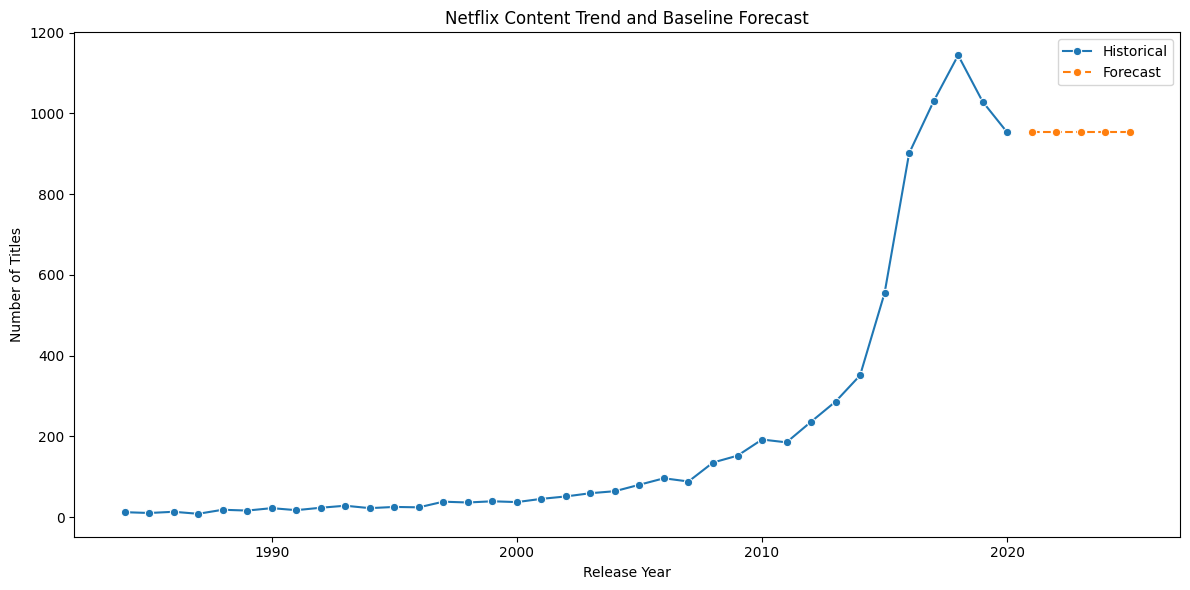

In [20]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=trend_data,
    x="release_year",
    y="content_count",
    marker="o",
    label="Historical"
)

sns.lineplot(
    data=future_forecast,
    x="release_year",
    y="forecast_count",
    marker="o",
    linestyle="--",
    label="Forecast"
)

plt.title("Netflix Content Trend and Baseline Forecast")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()

plt.tight_layout()
plt.show()

## Step 5: Interpret the results

The analysis shows a strong long-term increase in the number of Netflix titles represented in the dataset between 1984 and 2020.

Content growth became particularly strong from 2015 to 2018, when the number of titles increased from 555 to a peak of 1,144 in 2018. The count then declined to 1,029 in 2019 and 953 in 2020.

Three forecasting approaches were evaluated using the 2017–2020 test period. The naive baseline performed best, with an MAE of 138.00 and an RMSE of 153.93. Linear regression and Holt exponential smoothing produced substantially larger errors.

The naive model was therefore selected for the future forecast. Using the last complete observation of 953 titles in 2020, the model estimates approximately 953 titles per year for the 2021–2025 forecast period.

This forecast should be interpreted as a baseline estimate rather than a prediction of Netflix's actual future content production. The model assumes that the most recent observed level remains constant and therefore does not attempt to model changes in Netflix's strategy, market conditions, licensing decisions, or other external factors.

## Task 4 Summary

The release-year analysis identified a long-term increase in Netflix content represented in the dataset, with particularly rapid growth between 2015 and 2018. The highest observed count was 1,144 titles in 2018, followed by declines in 2019 and 2020.

Three forecasting approaches were tested: a naive baseline, linear regression, and Holt exponential smoothing. The naive baseline achieved the lowest MAE (138.00) and RMSE (153.93) on the 2017–2020 test period and was therefore selected as the best-performing model.

Using the complete 1984–2020 historical period, the selected baseline forecasts approximately 953 titles per year for 2021–2025.

The analysis demonstrates a complete trend prediction workflow involving historical aggregation, time-based train/test splitting, baseline forecasting, model comparison, future forecasting, and visualization.

### Key limitation

The selected model is intentionally simple and assumes that the most recent observed content level remains constant. It does not account for seasonality, external market factors, changes in Netflix's content strategy, or the fact that the dataset represents a specific catalogue snapshot rather than all Netflix content released globally.